# Ramen on CIFAR-100-C: evaluation and failure analysis

Runs **Ramen** and a **NoAdapt** baseline (zero-shot CLIP) on exactly the same test stream, then breaks down where Ramen helps and where it fails.
The code lives in `ramen_analysis.py` (`CIFAR100CExperiment`). Results are cached in `results/`, so you can re-run the plot cells without re-running the models.

In [43]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pick a free GPU; must be set before torch is imported

from ramen_analysis import CIFAR100CExperiment

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [44]:
exp = CIFAR100CExperiment(
    model='clip_vitbase16',
    tta_mode='mixed',      # 'mixed': one shuffled stream over all corruptions | 'single': each corruption separately, reset between
    batch_size=100,
    n_per_domain=None,     # None = whole dataset (10k images per corruption); e.g. 1000 for a quick run
    seed=0,
).load()

CIFAR100C: 15 corruptions x 10000 images, 100 classes, model=clip_vitbase16, mode=mixed


In [45]:
acc = exp.evaluate()   # pass use_cache=False to force a re-run
acc

NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR100C_clip_vitbase16_mixed_nall_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR100C_clip_vitbase16_mixed_nall_bs100_s0_Ramen.pkl


,NoAdapt,Ramen,delta
gaussian_noise,22.83,30.37,7.54
shot_noise,24.42,31.98,7.56
impulse_noise,29.58,42.94,13.36
defocus_blur,43.56,52.60,9.04
glass_blur,20.16,28.95,8.79
motion_blur,43.60,52.38,8.78
zoom_blur,48.64,55.74,7.10
snow,48.91,55.30,6.39
frost,50.48,54.40,3.92
fog,41.77,52.84,11.07


## 1. Which corruptions does Ramen struggle on?
Orange = NoAdapt, blue = Ramen, so the line between them is what adaptation changes. Corruptions are sorted with Ramen's worst at the top. **Bold** numbers on the right are corruptions where Ramen does *worse* than doing nothing.

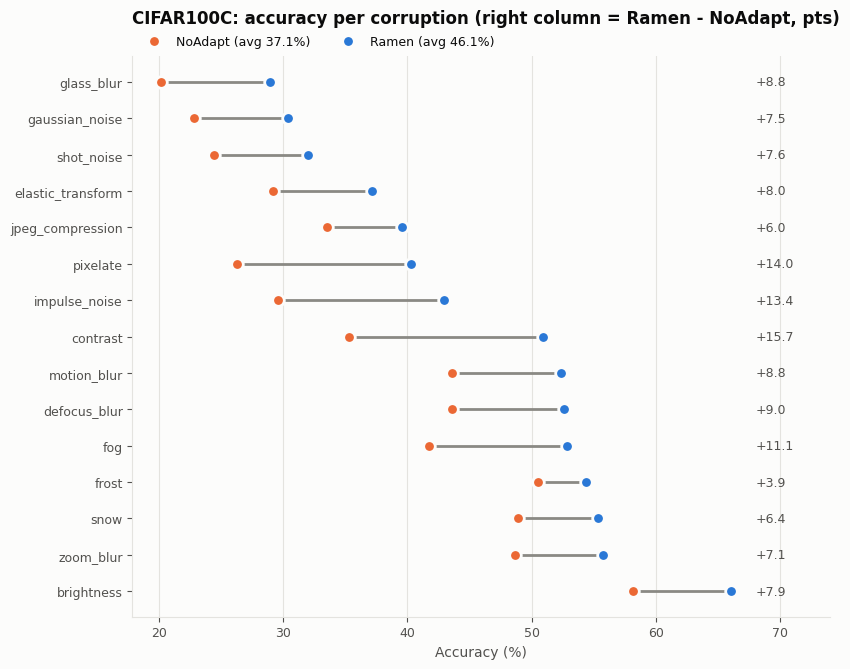

In [46]:
exp.plot_domain_accuracy();

## 2. Per-sample flips
The aggregate gain hides two opposing effects. Blue = samples Ramen **fixed** (NoAdapt wrong, Ramen right). Red = samples Ramen **broke** (NoAdapt right, Ramen wrong). A large red bar means harmful adaptation, even when the net gain is positive.

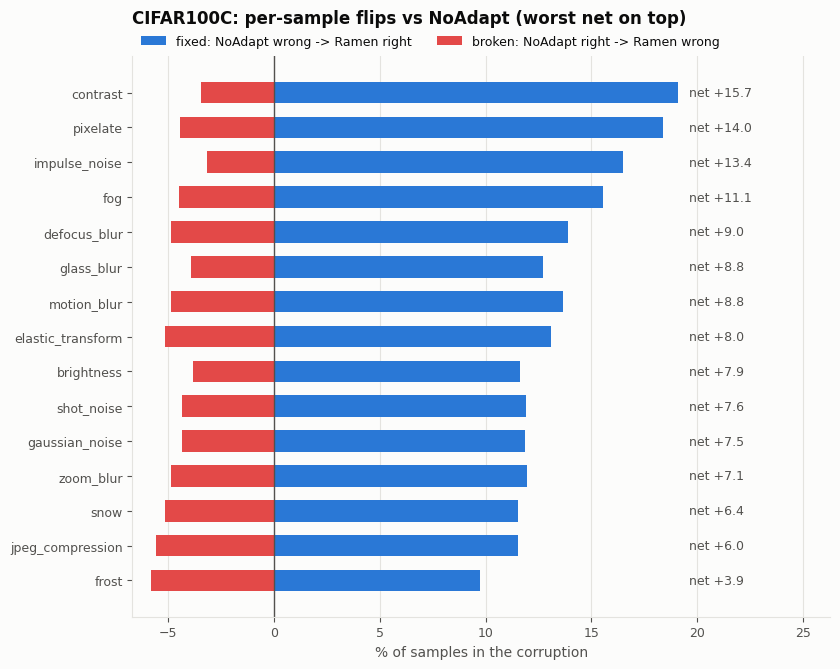

In [47]:
exp.plot_flips();

## 3. Which classes, under which corruptions?
Ramen − NoAdapt accuracy for each superclass (20 groups of 5 classes) and corruption. Red cells show where adaptation hurts. Rows are sorted with the worst at the top. The second heatmap shows Ramen's absolute accuracy.

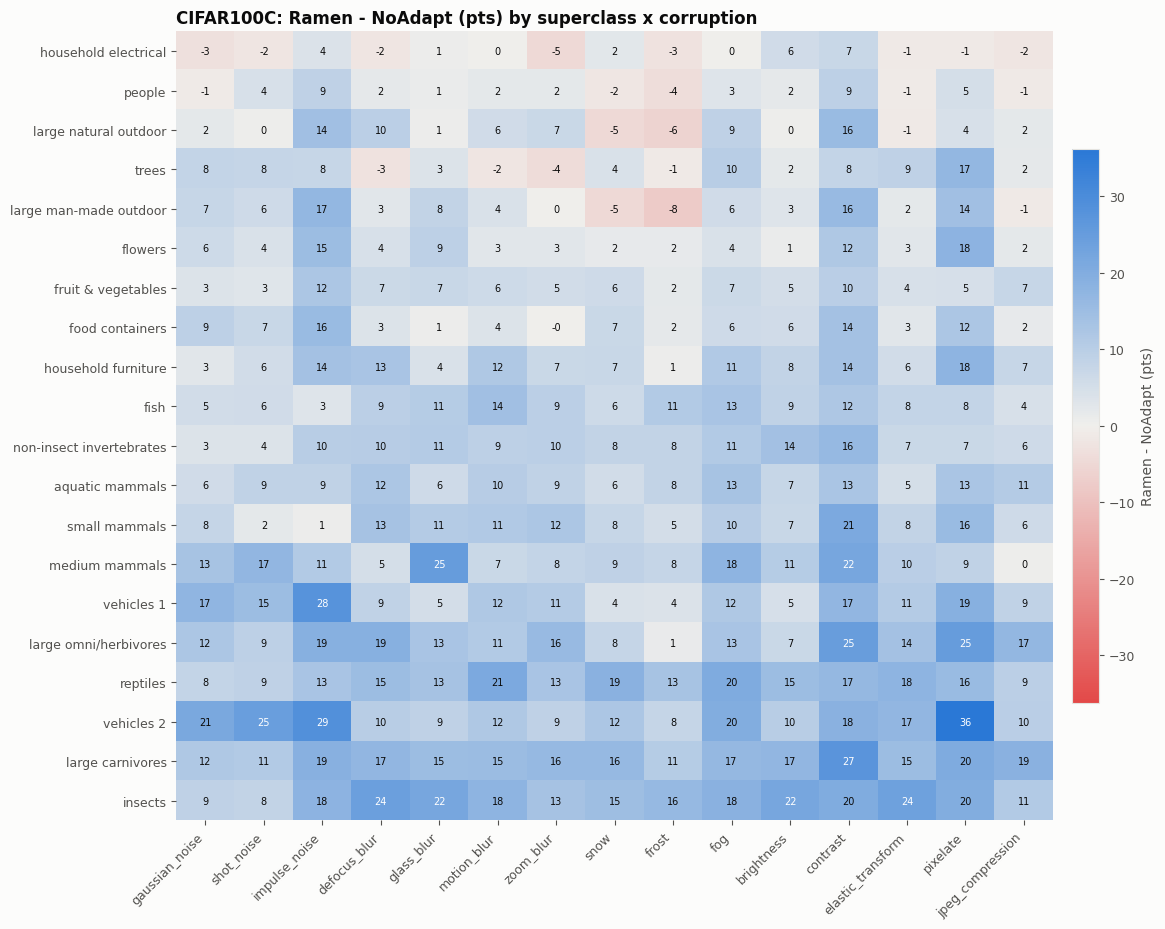

In [48]:
exp.plot_class_heatmap('delta');

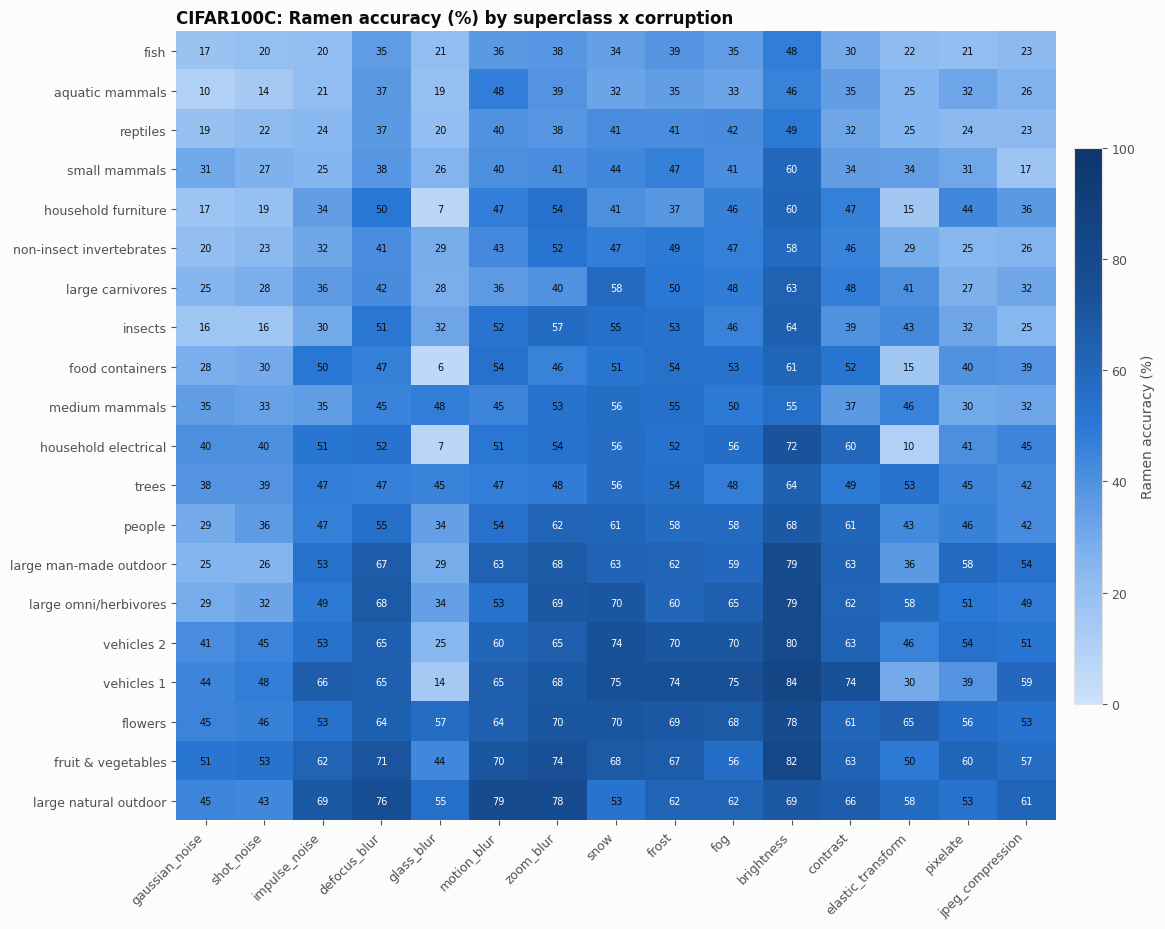

In [49]:
exp.plot_class_heatmap('Ramen');

With 20 superclasses you only see aggregates. To see the 25 individual classes Ramen hurts most, use `by_superclass=False`:

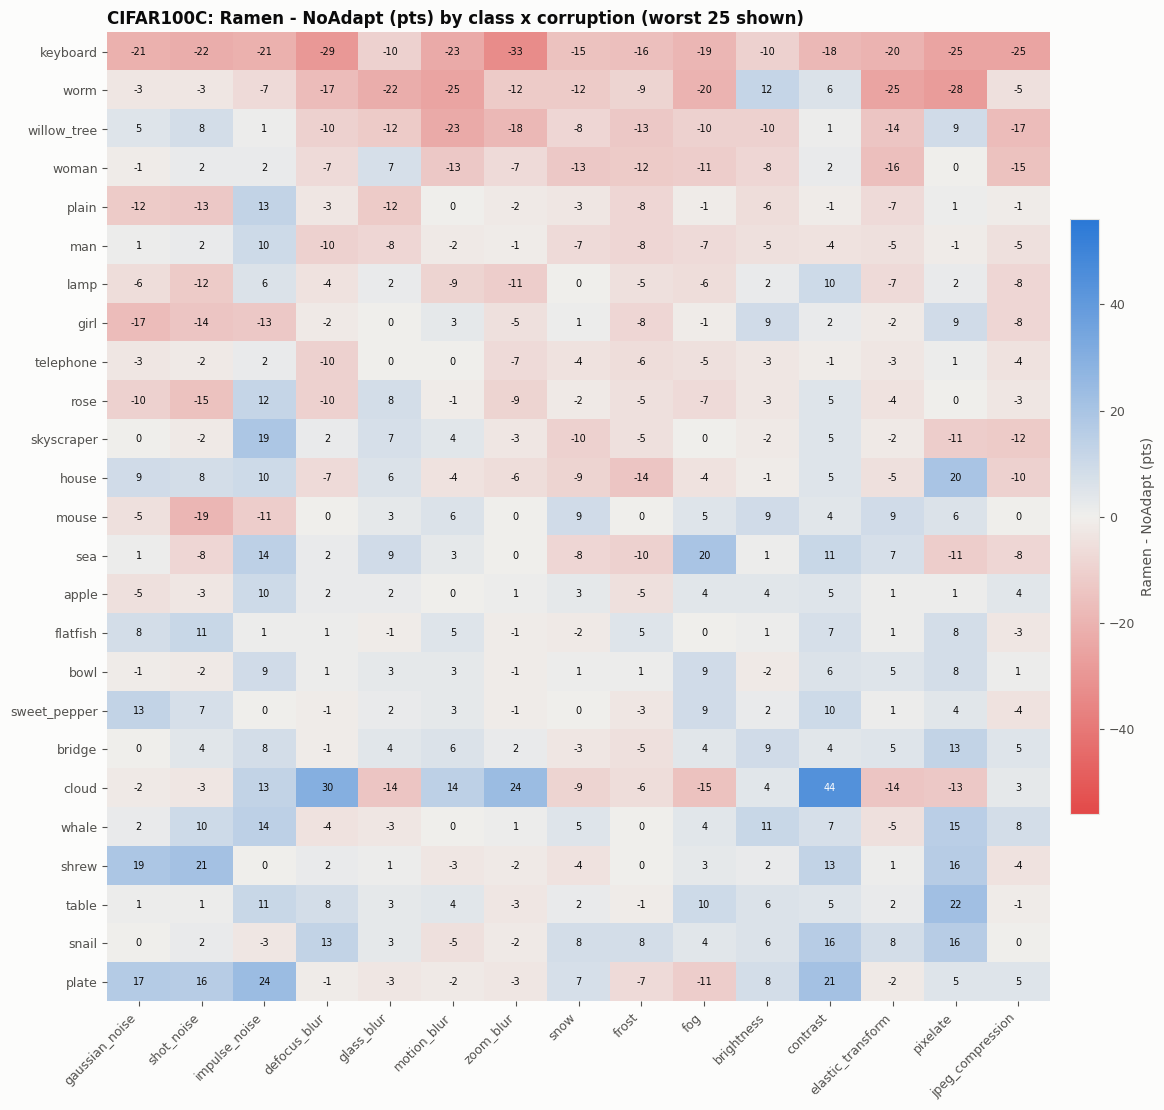

In [50]:
exp.plot_class_heatmap('delta', by_superclass=False, max_rows=25);

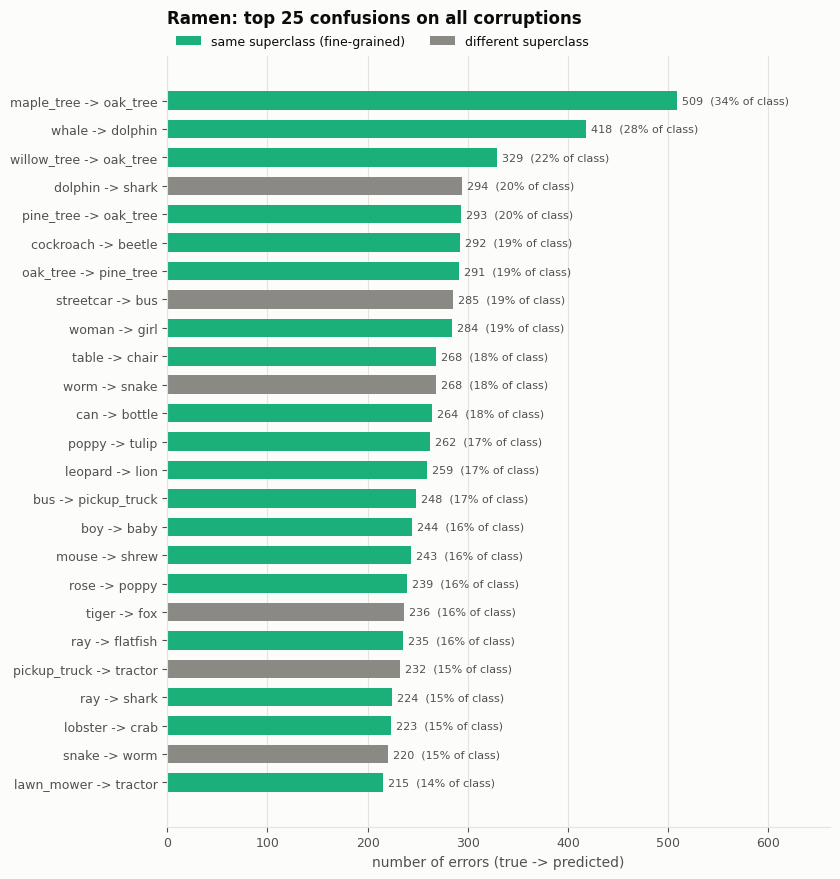

In [51]:
exp.plot_confusion();

## 4. Prediction bias / class collapse
Predicted share of each class minus its true share. Entropy-driven TTA tends to collapse onto a few "attractor" classes, which show up as large positive bars for Ramen.

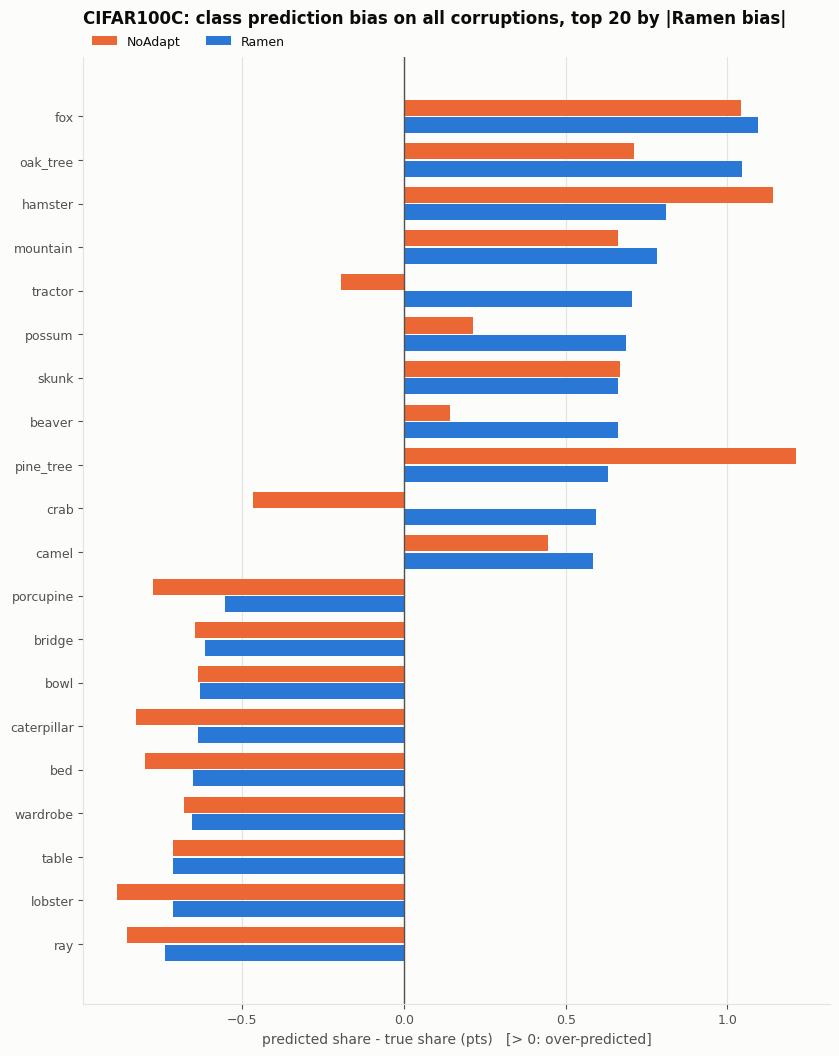

In [52]:
exp.plot_prediction_bias();

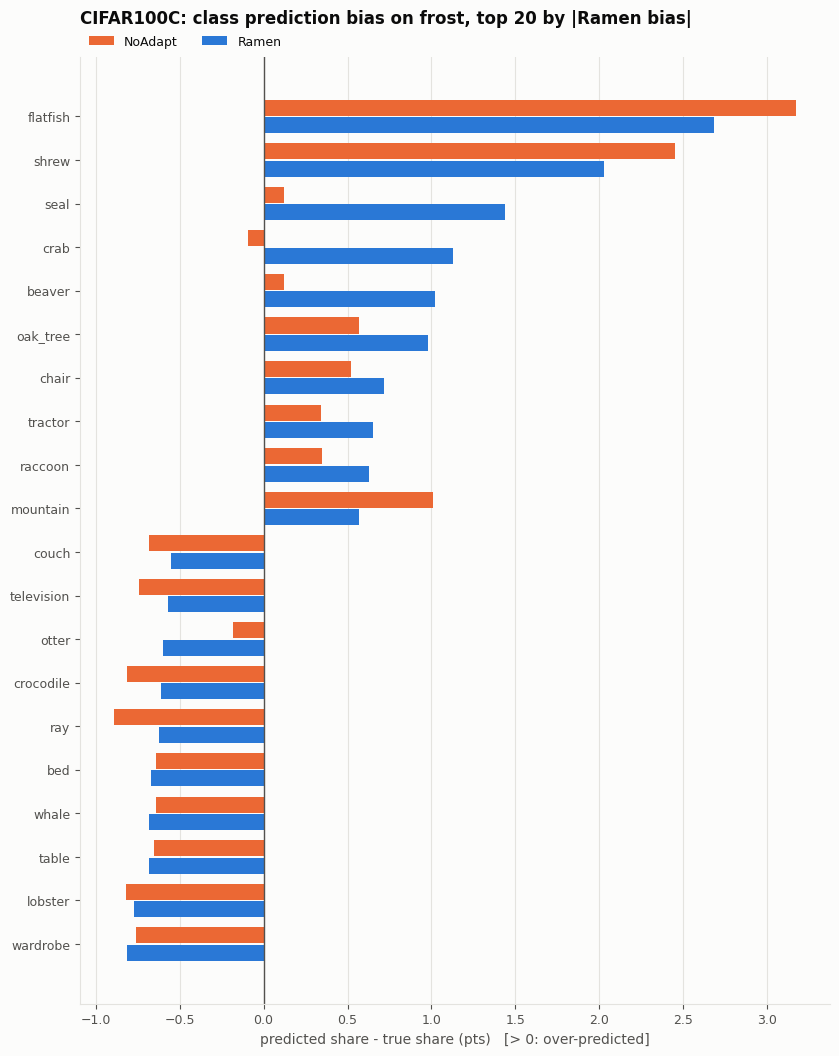

In [53]:
exp.plot_prediction_bias(domain=acc.drop('average')['delta'].idxmin());  # the corruption where Ramen gains least

## 5. What gets confused with what

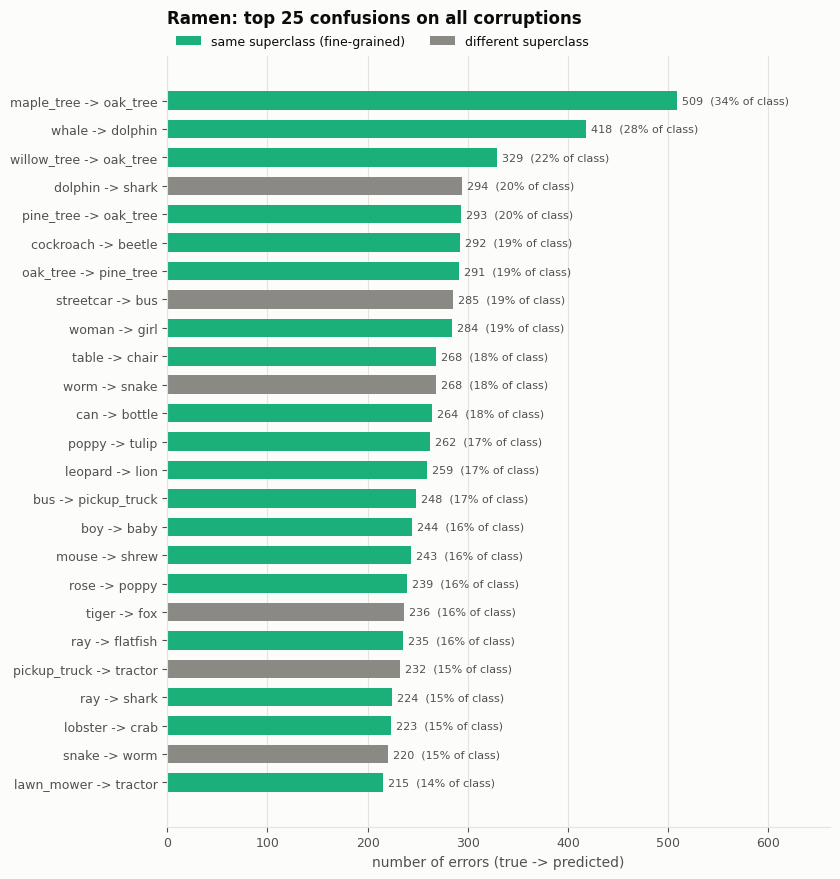

In [54]:
exp.plot_confusion();

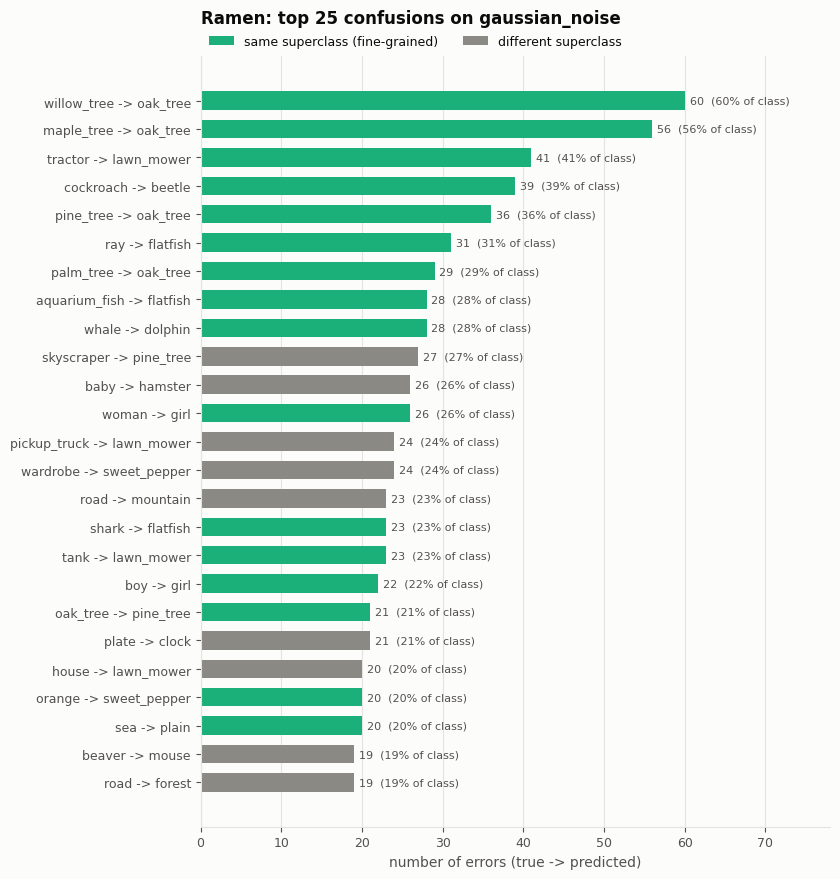

In [55]:
exp.plot_confusion(domain='gaussian_noise');

How fine-grained are the errors? This is the share of errors where the wrong prediction stays inside the true class's superclass (e.g. oak → maple, not oak → bus).

In [56]:
exp.error_granularity()

,NoAdapt % errors within superclass,Ramen % errors within superclass
gaussian_noise,20.3,24.6
shot_noise,20.8,26.3
impulse_noise,22.5,29.3
defocus_blur,28.0,32.3
glass_blur,15.1,19.9
motion_blur,27.2,30.1
zoom_blur,30.4,32.9
snow,30.3,34.3
frost,32.4,34.9
fog,29.0,34.8


## 6. Does Ramen degrade over time?
Top panel: rolling accuracy along the stream. Bottom panel: rolling Ramen − NoAdapt gap. A gap that shrinks or turns red later in the stream points to cache staleness or error accumulation. In `single` mode the model is reset at each dashed line.

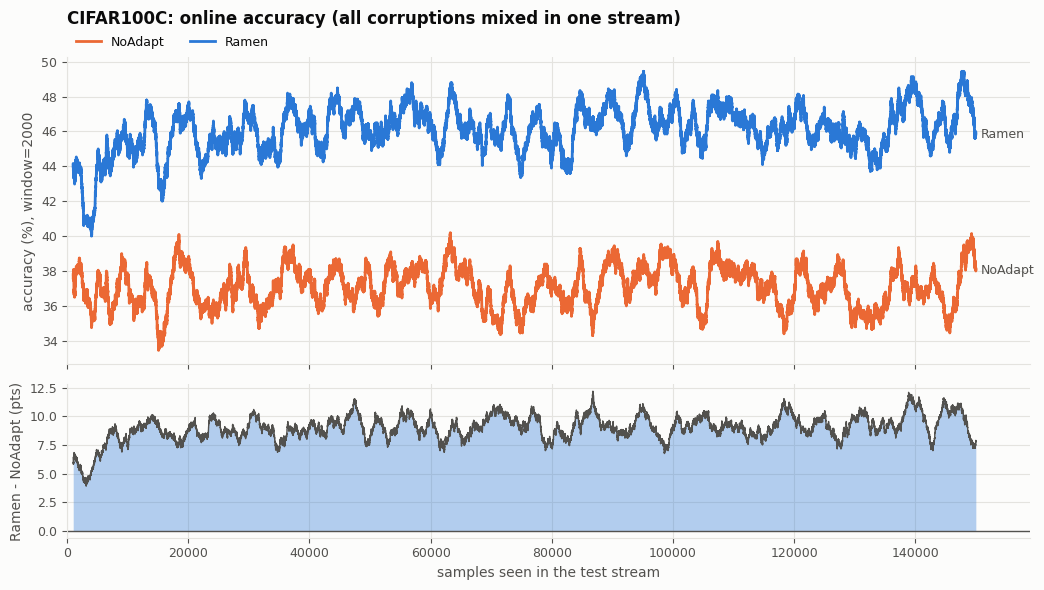

In [57]:
exp.plot_online_accuracy();

## 7. Calibration
Left: points below the diagonal mean the model is overconfident. Right: Ramen's confidence on wrong predictions. Errors made at high confidence are the most dangerous failures, because a confidence threshold won't catch them.

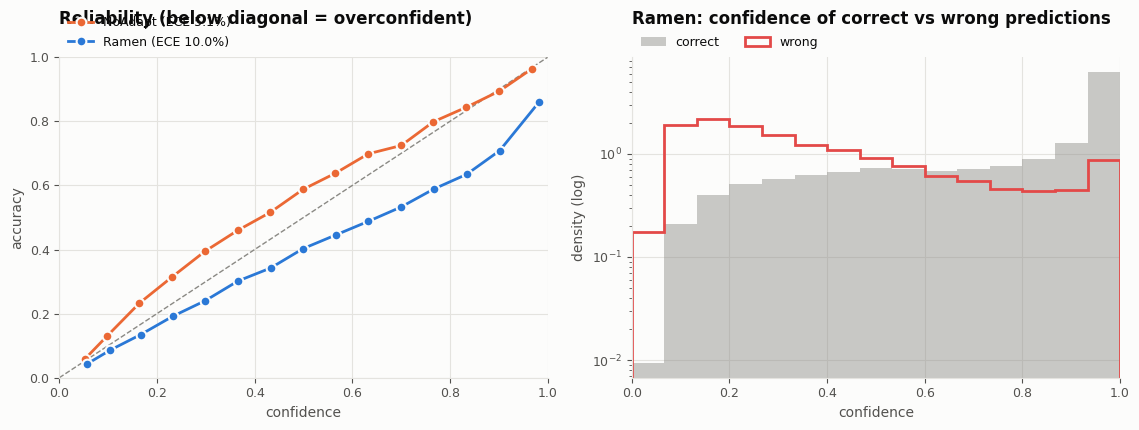

In [58]:
exp.plot_calibration();

## 8. Look at the failures
Images are sorted most-confident first. Captions show the corruption, the true class, and Ramen's prediction with its confidence.
`kind`: `'broken'` (Ramen broke a correct zero-shot prediction), `'both wrong'`, `'fixed'`, or `'wrong'` (any Ramen error).

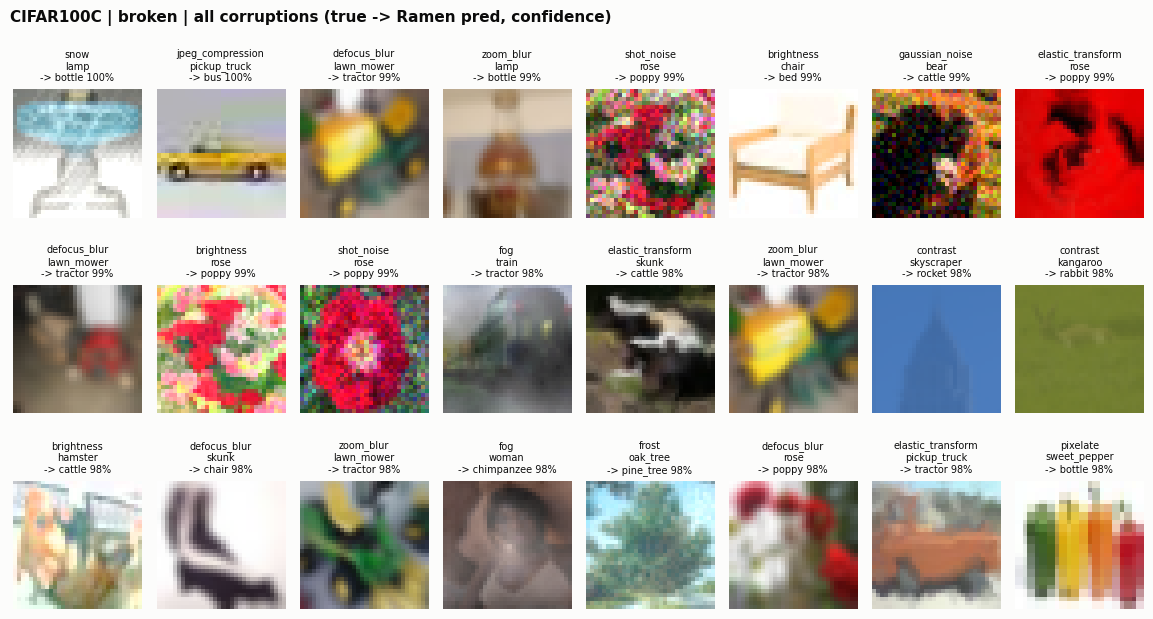

In [59]:
exp.show_failures(kind='broken', n=24);

worst corruption for Ramen: glass_blur


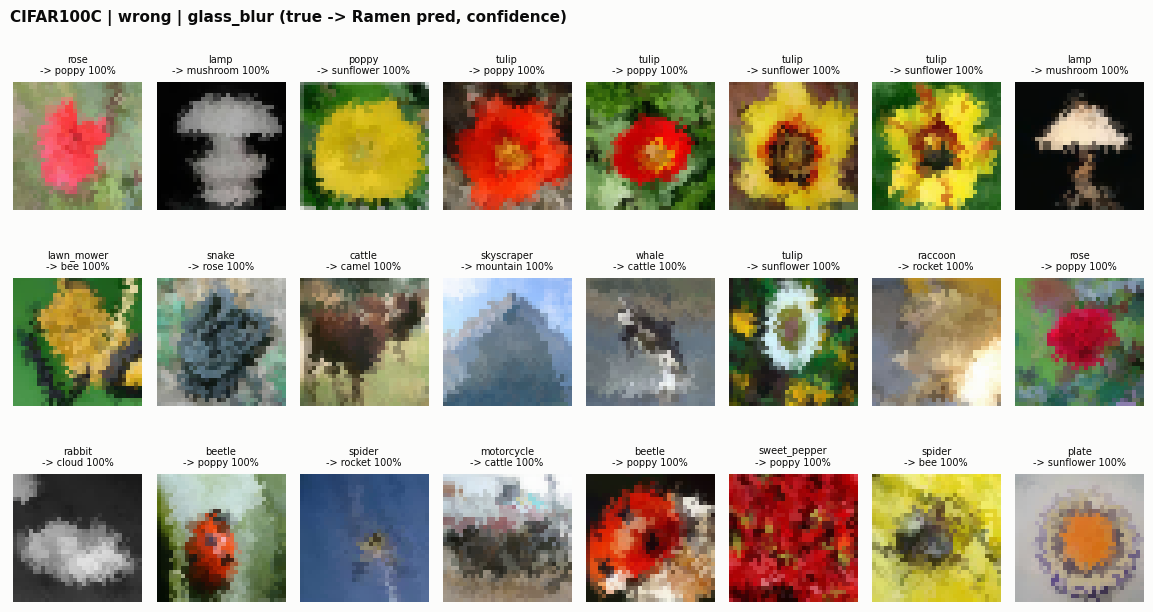

In [60]:
worst = acc.drop('average')['Ramen'].idxmin()
print('worst corruption for Ramen:', worst)
exp.show_failures(domain=worst, kind='wrong', n=24);

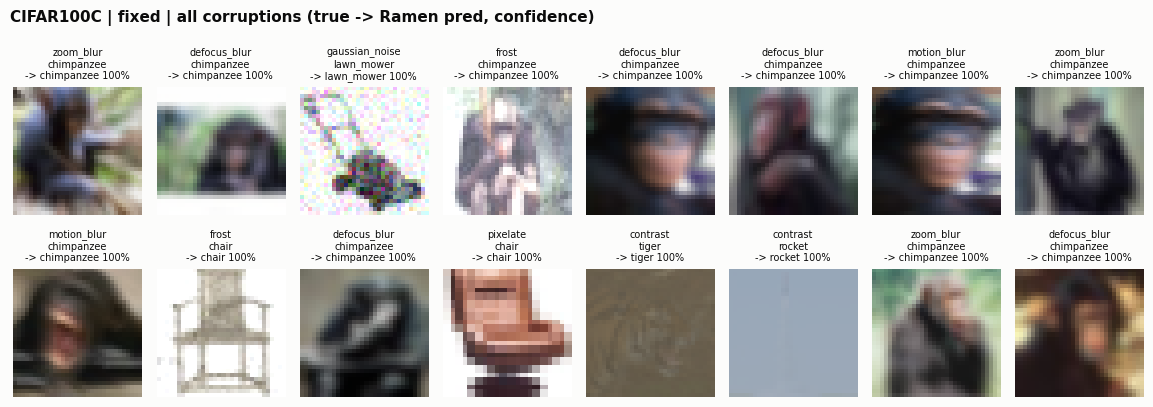

In [61]:
exp.show_failures(kind='fixed', n=16);

Images for the most confused pairs, one row per pair. A row labelled `true: A / Ramen: B` shows images whose true class is A that Ramen predicts as B. Each caption gives the corruption, Ramen's confidence in B, and what NoAdapt did on the same image: `right` (it predicted A), `same error` (it also predicted B), or the other wrong class it picked.
`order='confident'` shows the errors Ramen is surest about first; `order='borderline'` shows the ones where it barely picked B (low confidence, so other classes were close behind).

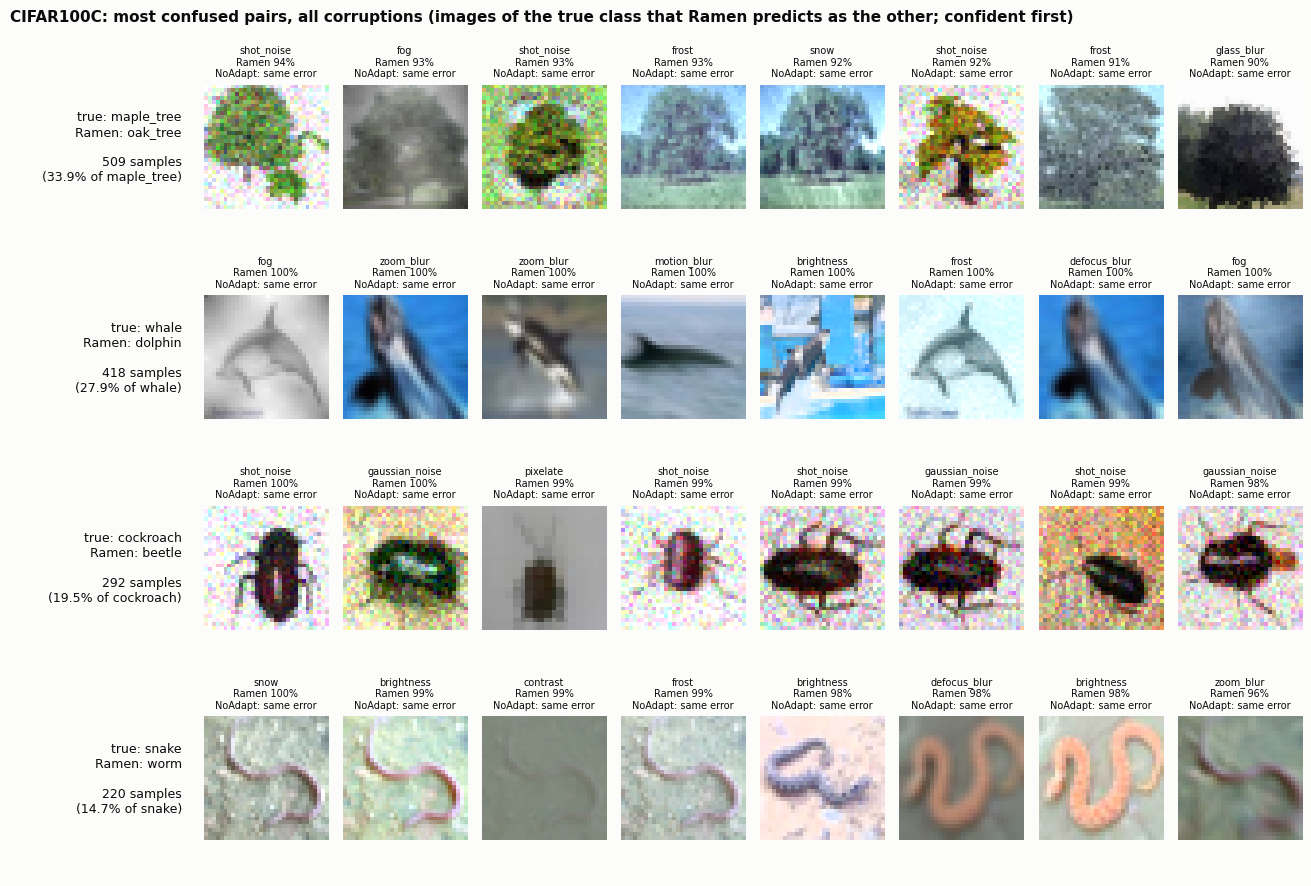

In [62]:
exp.show_confused_pairs(top_k=4, n=8);

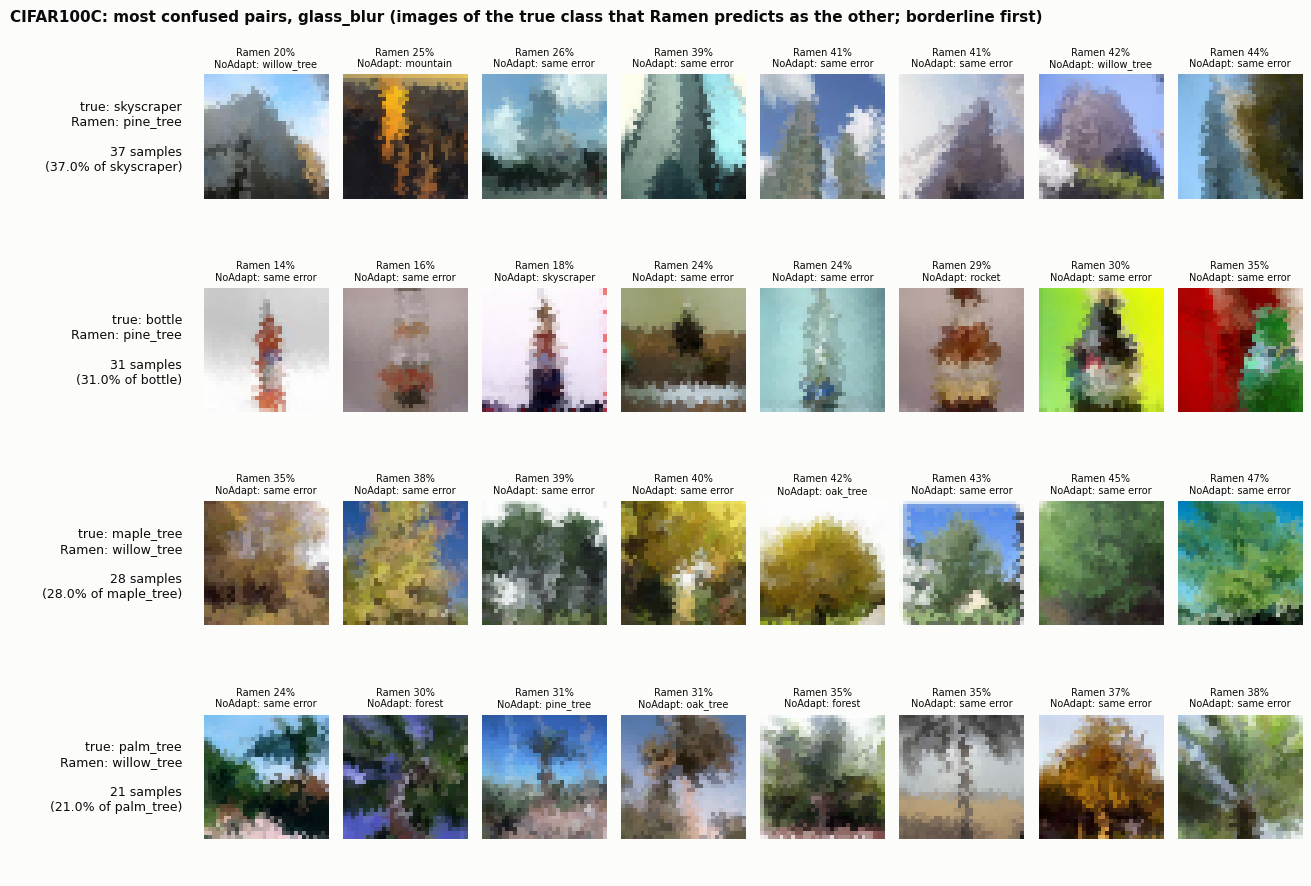

In [63]:
exp.show_confused_pairs(domain=worst, top_k=4, n=8, order='borderline');

## 9. Would "keep zero-shot when it is confident" help?
Post-hoc gate: use NoAdapt's prediction wherever its confidence is at least `tau`, and Ramen's elsewhere. This is exact for a gate that only skips a sample's own update, because the memory doesn't change. `oracle` is the ceiling for *any* per-sample choice between the two methods.

In [64]:
gate = exp.gate_sweep()
print(f"Ramen: {gate.attrs['Ramen']:.2f}   oracle (either right): {gate.attrs['oracle']:.2f}")
gate

Ramen: 46.10   oracle (either right): 50.63


,gated %,NoAdapt acc in gate,Ramen acc in gate,gated total acc,broken saved,fixed lost
tau,,,,,,
0.50,23.49,78.96,79.97,45.86,352,708
0.60,18.32,83.52,83.89,46.03,137,240
0.70,14.17,87.37,87.42,46.09,62,73
0.80,10.25,91.08,91.02,46.10,34,25
0.90,6.08,94.75,94.67,46.10,14,7
0.95,3.42,96.94,96.88,46.10,3,0
0.99,0.53,98.48,98.48,46.10,0,0


## 10. Would "don't adapt when zero-shot entropy is already low" help?
Same post-hoc gate as section 9, but the signal is zero-shot **entropy** instead of confidence: use NoAdapt's prediction wherever its entropy is at most `tau · ln C`, and Ramen's elsewhere. `ln C` is the largest possible entropy (all classes equally likely), so `tau` is a fraction of it and the same `tau` values work for any number of classes. `entropy threshold` is the cut-off in nats (`ln 100 ≈ 4.61` here). Low `tau` gates only the samples zero-shot is very sure about. (EATA uses the same scale, `0.4 · ln C`, for the opposite rule: it skips *high*-entropy samples.)
The columns mean the same as in section 9:
- `gated %`: share of samples kept at zero-shot.
- `broken saved`: gated samples where Ramen was wrong and zero-shot right.
- `fixed lost`: gated samples where Ramen was right and zero-shot wrong.
- Compare `gated total acc` with Ramen's accuracy printed above the table.

In [4]:
entropy_gate = exp.entropy_gate_sweep()   # taus=(0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6) by default
print(f"Ramen: {entropy_gate.attrs['Ramen']:.2f}   oracle (either right): {entropy_gate.attrs['oracle']:.2f}")
entropy_gate

Ramen: 46.10   oracle (either right): 50.63


,entropy threshold,gated %,NoAdapt acc in gate,Ramen acc in gate,gated total acc,broken saved,fixed lost
tau,,,,,,,
0.05,0.230,2.25,97.27,97.21,46.10,2,0
0.10,0.461,4.90,95.20,95.11,46.10,8,2
0.20,0.921,9.92,89.37,89.53,46.08,54,79
0.30,1.382,15.42,82.62,83.44,45.97,226,416
0.40,1.842,21.74,76.09,78.15,45.65,500,1171
0.50,2.303,28.52,70.63,73.62,45.24,965,2244
0.60,2.763,36.52,65.50,69.51,44.63,1615,3809
